# Ex2: Measured 190 GHz Active 2-Port

The Vector Fitting feature is demonstrated using a 2-port S-matrix of an active circuit measured from 140 GHz to 220 GHz. Additional explanations and background information can be found in the [Vector Fitting tutorial](../../tutorials/VectorFitting.ipynb).

In [1]:
import numpy as np

import skrf
from skrf.vectorFitting import VectorFitting

This example is a lot more tricky to fit, because the responses contain a few "bumps" and noise from the measurement. In such a case, finding a good number of initial poles can take a few iterations. A good alternative for such cases is the automatic vector fitting feature, `auto_fit()`, which automatically refines the number of poles until a good fit is achieved.

Load the Network from a Touchstone file and create the Vector Fitting instance and start the automatic fit:

In [2]:
nw = skrf.network.Network('./190ghz_tx_measured.S2P')
vf = VectorFitting(nw)
vf.auto_fit()

The function `plot_convergence()` can be helpful to examine the convergence and see if something was going wrong. Important parameters to check are the number of iterations until convergence and the final model order.

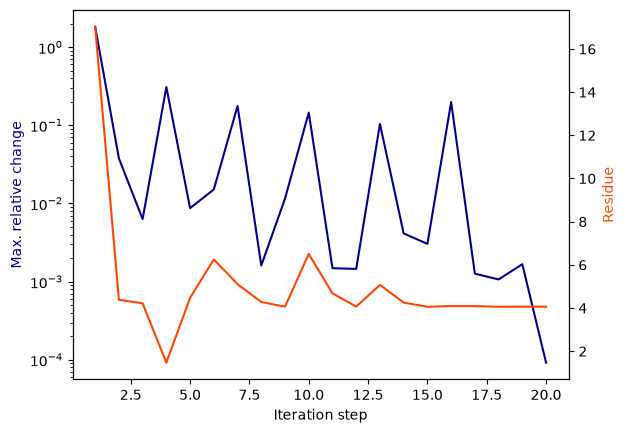

In [3]:
vf.plot_convergence()

In [4]:
print(f'model order = {vf.get_model_order(vf.poles)}')
print(f'n_poles_real = {np.sum(vf.poles.imag == 0.0)}')
print(f'n_poles_complex = {np.sum(vf.poles.imag > 0.0)}')

model order = 21
n_poles_real = 1
n_poles_complex = 10


Checking the results by comparing the model responses to the original sampled data indicates a successful fit, which is also indicated by a small rms error (less than 0.05):

In [5]:
vf.get_rms_error()

np.float64(0.013618943572754267)

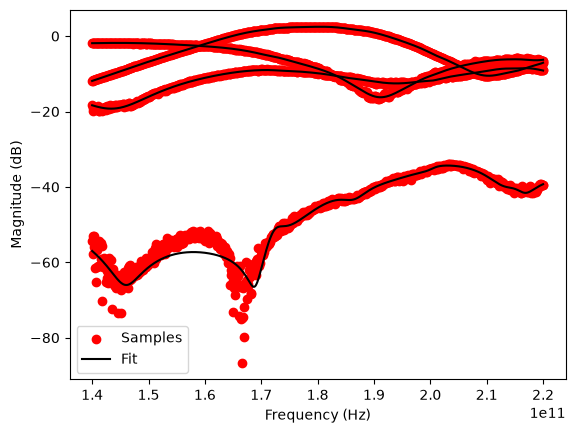

In [6]:
# plot frequency responses
vf.plot_s_db()

It is a good idea to also check the model response well outside the original frequency range.

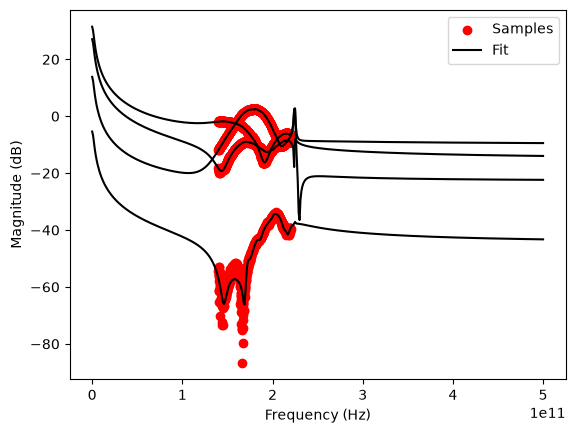

In [7]:
freqs = np.linspace(0, 500e9, 501) # plot model response from dc to 500 GHz
vf.plot_s_db(freqs=freqs)